# Data Cleaning & Preparation — The 80% Nobody Talks About

Every ML tutorial makes it look easy: load data, call `.fit()`, done. 🎩✨

Real data does **not** arrive in a tidy little table. It shows up with missing cells, typos, prices stored as text, impossible ages, duplicate rows, and columns you don't need. Before a model can learn *anything*, **you** have to fix all of that.

In this notebook we'll take a genuinely messy **loan approval** dataset, clean it step by step, and only *then* train a classifier. Keep an eye on how much work happens **before** the model — that's the whole point.

> **The scenario:** a bank wants to predict whether a loan application will be **Approved** or **Rejected**, based on the applicant's age, income, credit score, employment, and more.

## First — survey the damage 🔍

Load the raw file and *look* at it before touching anything. Good data scientists are detectives first.

In [3]:
import pandas as pd

df = pd.read_csv("loan_data.csv")
df.head(10)

,applicant_id,name,age,income,credit_score,loan_amount,employment_status,married,gender,approved
0,APP1170,Raj Smith,NaN,"$66,400",NaN,89100.0,Unemployed,No,Female,Rejected
1,APP1177,Omar Silva,25.0,"$75,700",645.0,228600.0,Employed,NaN,Male,Approved
2,APP1132,Mei Khan,24.0,"$26,400",580.0,5000.0,employed,Yes,Female,Approved
3,APP1193,Liam Ali,28.0,"$78,500",NaN,272600.0,Employed,No,Female,Approved
4,APP1102,Raj Kumar,35.0,NaN,573.0,159000.0,employed,N,Female,Rejected
5,APP1182,Raj Silva,26.0,"$12,000",574.0,78000.0,Unemployed,Y,Male,Rejected
6,APP1189,Liam Smith,37.0,"$63,200",692.0,5000.0,employed,Yes,male,Approved
7,APP1073,Sara Brown,NaN,"$104,000",784.0,170200.0,employed,no,Male,Approved
8,APP1051,John Smith,56.0,"$60,500",780.0,182400.0,employed,Y,M,Approved
9,APP1185,Nina Silva,23.0,"$76,700",NaN,13700.0,Employed,Yes,F,Approved


In [4]:
# shape + column types: notice 'income' is an OBJECT (text!), not a number
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   applicant_id       212 non-null    str    
 1   name               212 non-null    str    
 2   age                194 non-null    float64
 3   income             202 non-null    str    
 4   credit_score       195 non-null    float64
 5   loan_amount        212 non-null    float64
 6   employment_status  201 non-null    str    
 7   married            200 non-null    str    
 8   gender             202 non-null    str    
 9   approved           212 non-null    str    
dtypes: float64(3), str(7)
memory usage: 26.2 KB


In [5]:
# how many missing values per column?
df.isna().sum()

applicant_id          0
name                  0
age                  18
income               10
credit_score         17
loan_amount           0
employment_status    11
married              12
gender               10
approved              0
dtype: int64

In [6]:
# any fully duplicated rows?
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 12


Yikes. 😬 Missing values everywhere, `income` is text, there are duplicate rows, and (as we'll see) some ages and credit scores are physically impossible. Let's fix it — **one problem per step**.

## Step 1 — Drop columns we don't need

`applicant_id` and `name` don't help predict anything (and `name` is personal info we shouldn't feed the model). Out they go.

In [7]:
df = df.drop(columns=['applicant_id', 'name'])
df.columns.tolist()

['age',
 'income',
 'credit_score',
 'loan_amount',
 'employment_status',
 'married',
 'gender',
 'approved']

## Step 2 — Remove duplicate rows

Duplicates let the same applicant vote twice and quietly bias the model. Drop them.

In [8]:
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows. {len(df)} rows remain.")

Removed 12 duplicate rows. 200 rows remain.


## Step 3 — Fix data types (`income` is text!)

`income` looks like `"$54,000"` — a **string**. You can't do math on strings. Strip the `$` and commas, then convert to a number. Anything that still isn't numeric (like `?`) becomes `NaN`, which we'll deal with in Step 6.

In [9]:
print("Before:", df['income'].head(3).tolist())

df['income'] = (
    df['income'].astype(str)
      .str.replace(r'[$,]', '', regex=True)   # remove $ and commas
      .str.strip()
)
df['income'] = pd.to_numeric(df['income'], errors='coerce')  # text -> number, junk -> NaN

print("After: ", df['income'].head(3).tolist(), "| dtype:", df['income'].dtype)

Before: ['$66,400', '$75,700', '$26,400']
After:  [66400.0, 75700.0, 26400.0] | dtype: float64


## Step 4 — Standardize inconsistent categories

The same thing is written many ways: `Male` / `male` / `M`. To a computer those are three different values! Let's collapse each column to one clean set of labels.

In [10]:
# BEFORE: look at the mess
df['gender'].value_counts(dropna=False)

gender
Male      37
M         34
female    34
male      31
F         28
Female    26
NaN       10
Name: count, dtype: int64

In [11]:
df['gender'] = df['gender'].astype(str).str.strip().str.lower().map(
    {'male': 'Male', 'm': 'Male', 'female': 'Female', 'f': 'Female'}
)
df['married'] = df['married'].astype(str).str.strip().str.lower().map(
    {'yes': 'Yes', 'y': 'Yes', 'no': 'No', 'n': 'No'}
)
emp_map = {
    'employed': 'Employed',
    'self employed': 'Self-Employed', 'self-employed': 'Self-Employed',
    'unemployed': 'Unemployed',
}
df['employment_status'] = df['employment_status'].astype(str).str.strip().str.lower().map(emp_map)

# AFTER: clean and consistent
df['gender'].value_counts(dropna=False)

gender
Male      102
Female     88
NaN        10
Name: count, dtype: int64

## Step 5 — Fix impossible values (outliers)

Some rows claim an **age of 200** or a **credit score of 9999**. Those aren't real — they're data-entry errors. A sensible move: mark anything outside a valid range as `NaN` and let the next step fill it in.

- valid age: **18–100**
- valid credit score: **300–850**

In [12]:
import numpy as np

print("Impossible ages before:", sorted(df.loc[(df.age < 18) | (df.age > 100), 'age'].dropna().tolist()))

df.loc[(df['age'] < 18) | (df['age'] > 100), 'age'] = np.nan
df.loc[(df['credit_score'] < 300) | (df['credit_score'] > 850), 'credit_score'] = np.nan

print("Fixed. Those cells are now NaN (handled next).")

Impossible ages before: [-5.0, -5.0, 200.0, 200.0]
Fixed. Those cells are now NaN (handled next).


## Step 6 — Handle missing values

You generally can't feed `NaN` to a model. Two common choices: **drop** the rows, or **impute** (fill in a reasonable estimate). Dropping would throw away a lot of data here, so we impute:
- **numeric** columns → fill with the **median** (robust to outliers)
- **categorical** columns → fill with the **mode** (most common value)

In [13]:
num_cols = ['age', 'income', 'credit_score', 'loan_amount']
for c in num_cols:
    df[c] = df[c].fillna(df[c].median())

for c in ['gender', 'employment_status', 'married']:
    df[c] = df[c].fillna(df[c].mode()[0])

print("Total missing values left:", df.isna().sum().sum())

Total missing values left: 0


## Step 7 — Encode categories as numbers

Models do math, and math needs numbers — not `"Employed"`. We:
- map the **target** `approved` to `1` / `0`
- **one-hot encode** the categorical features (each category becomes its own 0/1 column)

In [14]:
df['approved'] = df['approved'].map({'Approved': 1, 'Rejected': 0})
df = pd.get_dummies(df, columns=['gender', 'employment_status', 'married'], drop_first=True)

df.head()

,age,income,credit_score,loan_amount,approved,gender_Male,employment_status_Self-Employed,employment_status_Unemployed,married_Yes
0,41.0,66400.0,665.5,89100.0,0,False,False,True,False
1,25.0,75700.0,645.0,228600.0,1,True,False,False,True
2,24.0,26400.0,580.0,5000.0,1,False,False,False,True
3,28.0,78500.0,665.5,272600.0,1,False,False,False,False
4,35.0,51150.0,573.0,159000.0,0,False,False,False,False


## Step 8 — Normalize the numeric features

`age` is ~20–65 but `income` runs into the tens of thousands. Left unscaled, income would *shout* and age would *whisper*. **Standardizing** (mean 0, standard deviation 1) puts every feature on a level playing field.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
df[num_cols].head()

,age,income,credit_score,loan_amount
0,-0.098160,0.670402,0.052355,-0.724918
1,-1.412433,1.125193,-0.176488,0.892336
2,-1.494575,-1.285690,-0.902087,-1.699909
3,-1.166007,1.262119,0.052355,1.402438
4,-0.591012,-0.075358,-0.980228,0.085448


## Step 9 — *Finally*, train the model 🚀

Everything above was preparation. The actual machine-learning part? Look how short it is.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X = df.drop(columns=['approved'])
y = df['approved']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print(f"Test accuracy: {model.score(X_test, y_test):.2f}")

Test accuracy: 0.75


## Step 10 — Classification Report 

Print the classification report

In [20]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.78      0.78      0.78        23
           1       0.71      0.71      0.71        17

    accuracy                           0.75        40
   macro avg       0.74      0.74      0.74        40
weighted avg       0.75      0.75      0.75        40



## The reality check 📊

This notebook is a microcosm of real ML work. Industry surveys of data scientists find the same thing over and over: the **vast majority** of the job is finding, cleaning, and preparing data — *not* the modelling everyone imagines.

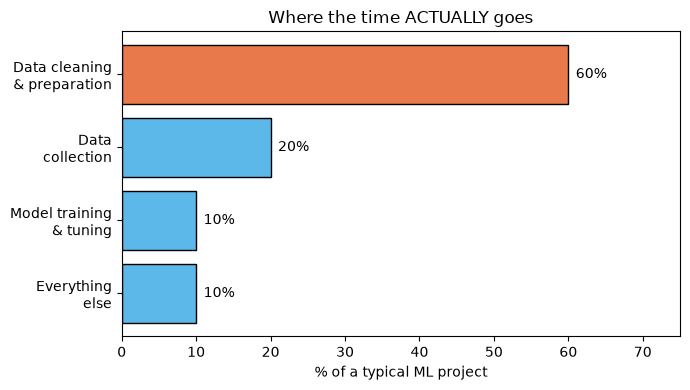

In [21]:
import matplotlib.pyplot as plt

tasks = ['Data cleaning\n& preparation', 'Data\ncollection',
         'Model training\n& tuning', 'Everything\nelse']
share = [60, 20, 10, 10]  # approximate, typical ML project
bar_colors = ['#E8794B', '#5BB8E8', '#5BB8E8', '#5BB8E8']

plt.figure(figsize=(7, 4))
plt.barh(tasks, share, color=bar_colors, edgecolor='k')
plt.gca().invert_yaxis()
plt.xlabel('% of a typical ML project')
plt.title('Where the time ACTUALLY goes')
for i, v in enumerate(share):
    plt.text(v + 1, i, f'{v}%', va='center')
plt.xlim(0, 75)
plt.tight_layout()
plt.show()

*(Figures are approximate and vary by survey — but the shape is always the same: cleaning dominates.)*

In **this very notebook**: **8 steps** of cleaning vs **~2 lines** of modelling. That ratio isn't an accident — it's the job.

## Recap
The clean-up toolkit you just used:
1. **Drop** useless / sensitive columns
2. **Remove duplicates** (`drop_duplicates`)
3. **Fix data types** (text `"$54,000"` → number)
4. **Standardize categories** (`Male`/`male`/`M` → `Male`)
5. **Fix impossible values / outliers** (age 200 → `NaN`)
6. **Handle missing values** (impute median / mode)
7. **Encode categories** (one-hot + map the target)
8. **Normalize / scale** (`StandardScaler`)
9. **…then** train the model — the quickest part of all

**The takeaway:** AI/ML engineers spend most of their time as **data janitors**, not model wizards. Clean data is the real superpower. 🧹